# Persona ensemble with a steered Yes/No readout

Each step the population is $N$ personas $i$ drawn uniformly from a fixed pool (the random choice; its law does not depend on the control).
Agent $i$ answers "Would you take the bus to work tomorrow?" and its output is

$$f_i(\alpha) = P_\text{LLM}(\text{Yes} \mid \text{persona } i, \alpha) = \sigma(\ell_\text{Yes} - \ell_\text{No}),$$

where 
- $\alpha$ is the signal from the controller modifying the agent's (LLM's) sentiment in a differentiable way (see Activation/sentiment steering: https://arxiv.org/abs/2312.06681; the residual stream at layer $L_s$ gets $h \mathrel{+}= \alpha v$ at every position. $v$ is a CAA vector, the mean hidden state on the answer token "Yes" minus that on "No")
- $\ell$ are the next-token logits 
- $\sigma$ the logistic function. 

$f_i$ is deterministic and smooth in $\alpha$. The population output is $y = \frac1N\sum_i f_i(\alpha)$.

Loop: $r \to$ A1 ($e = r - y$) $\to$ C (PI, $\alpha$) $\to$ P1 ($y$) $\to$ A2 $\to$ Z $\to$ F $\to$ A1.

In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath("../.."))
import itertools
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

from humancompatible.interconnect.simulators.simulation import Simulation
from humancompatible.interconnect.simulators.nodes.reference import ReferenceSignal
from humancompatible.interconnect.simulators.nodes.aggregator import Aggregator
from humancompatible.interconnect.simulators.nodes.controller import Controller
from humancompatible.interconnect.simulators.nodes.population import Population
from humancompatible.interconnect.simulators.nodes.delay import Delay
from humancompatible.interconnect.simulators.nodes.filter import Filter
from humancompatible.interconnect.simulators.logic.delays.exponentialSmoothingDelay import ESDelayLogic
from humancompatible.interconnect.simulators.logic.controllers.pi_controller import PiControllerLogic
from tests.contractionTests.contraction_test import get_factor_from_list

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"   # one forward + backward per step; 1.5B is ~3x slower on CPU
tok = AutoTokenizer.from_pretrained(MODEL)
tok.padding_side = "left"   # last position = answer position for every row
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).eval()
for p in model.parameters():
    p.requires_grad_(False)
YES, NO = tok.encode("Yes")[0], tok.encode("No")[0]

QUESTION = "Would you take the bus to work tomorrow? Answer with Yes or No."
POOL = [f"You are a {age}-year-old {job} who lives {home} and you {car}."
        for age, job, home, car in itertools.product(
            [19, 27, 34, 45, 71],
            ["nurse", "software developer", "student", "plumber", "teacher", "farmer"],
            ["in the city centre", "in a suburb", "in a small village"],
            ["own a car", "do not own a car"])]

def prompts(idx, answer=""):
    return [tok.apply_chat_template([{"role": "system", "content": POOL[i]}, {"role": "user", "content": QUESTION}],
                                    tokenize=False, add_generation_prompt=True) + answer for i in idx]
len(POOL)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

180

In [ ]:
LAYER = 12      # ~1/3 of the 24 layers
N_VEC = 64
rng = np.random.default_rng(0)
idx = rng.choice(len(POOL), N_VEC, replace=False)

@torch.no_grad()
def answer_states(answer):
    enc = tok(prompts(idx, answer), return_tensors="pt", padding=True)
    return model.model(**enc, output_hidden_states=True).hidden_states[LAYER + 1][:, -1].mean(0)

V = answer_states("Yes") - answer_states("No")
print(f"|v| = {V.norm():.1f}")

|v| = 32.3


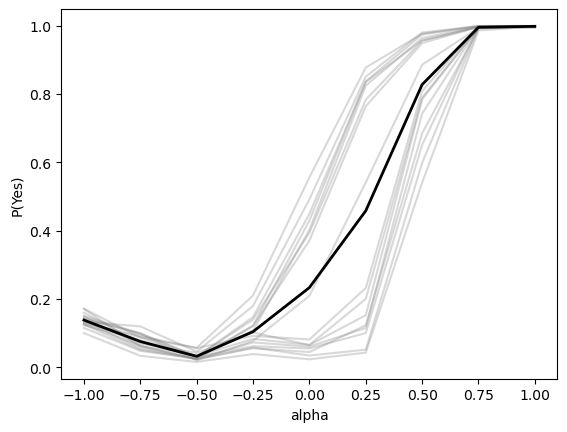

In [ ]:
def p_yes(idx, alpha):
    # alpha may carry a gradient; the hook adds alpha * v at every position of layer LAYER
    hook = model.model.layers[LAYER].register_forward_hook(lambda mod, args, out: out + alpha * V)
    try:
        logits = model(**tok(prompts(idx), return_tensors="pt", padding=True)).logits[:, -1]
    finally:
        hook.remove()
    return torch.sigmoid(logits[:, YES] - logits[:, NO])

ALPHAS = np.linspace(-1, 1, 9)
idx = rng.choice(len(POOL), 16, replace=False)
with torch.no_grad():
    F = np.array([p_yes(idx, a).numpy() for a in ALPHAS])   # (alpha, persona)
plt.plot(ALPHAS, F, color="grey", alpha=0.3)
plt.plot(ALPHAS, F.mean(1), color="k", lw=2)
plt.xlabel("alpha"); plt.ylabel("P(Yes)");

In [ ]:
KAPPA = 0.5     # the mean curve has slope ~2 near alpha=0.1, so kappa*slope ~1
N_AGENTS = 8
STEPS = 40
R = 0.5

In [ ]:
class AgentLogic:
    def __init__(self, seed=None):
        self.tensors = {"alpha": torch.tensor([0.0])}
        self.variables = ["alpha"]
        self.rng = np.random.default_rng(seed)

    # for each agent in population, randomly sample a personality from the pool 
    # and compute average probability of "yes", applying the alpha signal from the controller
    def forward(self, values, number_of_agents):
        alpha = values["alpha"]
        idx = self.rng.choice(len(POOL), number_of_agents)   # the random choice, independent of alpha
        a = alpha.detach().requires_grad_()
        y = p_yes(idx, a).mean()
        g, = torch.autograd.grad(y, a)
        # value y, gradient g wrt alpha: keeps the LLM graph out of the node history
        return (y.detach() + g * (alpha - alpha.detach())).reshape(1)


class PersonaSim(Simulation):
    class ErrorLogic:   # A1: e = r + F, cut from the past so the Jacobian is one pass
        def __init__(self):
            self.tensors = []
        def forward(self, tensors):
            return torch.stack([t.detach().sum() for t in tensors]).sum().reshape(1).requires_grad_()

    class SumLogic:   # A2
        def __init__(self):
            self.tensors = []
        def forward(self, tensors):
            tensors = tensors if isinstance(tensors, list) else [tensors]
            return torch.stack([t.sum() for t in tensors]).sum().reshape(1)

    class FilterLogic:   # F = -y
        def __init__(self):
            self.tensors = {"S": torch.tensor([0.0])}
            self.variables = ["S"]
        def forward(self, values):
            return -values["S"]

    def __init__(self, reference_signal=0.5, weights=None, alpha0=0.0, kappa=KAPPA, n_agents=N_AGENTS, seed=None):
        super().__init__()
        r = ReferenceSignal(name="r")
        r.set_reference_signal(torch.tensor(float(reference_signal)))
        a1 = Aggregator(name="A1", logic=self.ErrorLogic())
        pi = PiControllerLogic(kappa=kappa, alpha=0.0)   # alpha=0: pure integrator, alpha_k = alpha_{k-1} + kappa e_k
        pi.tensors["pi_prev"] = torch.tensor([float(alpha0)])
        c = Controller(name="C", logic=pi)
        p1 = Population(name="P1", logic=AgentLogic(seed), number_of_agents=n_agents)
        a2 = Aggregator(name="A2", logic=self.SumLogic())
        z = Delay(name="Z", logic=ESDelayLogic(alpha=1.0))   # pass-through
        f = Filter(name="F", logic=self.FilterLogic())
        self.system.add_nodes([r, a1, c, p1, a2, z, f])
        for u, w in [(r, a1), (a1, c), (c, p1), (p1, a2), (a2, z), (z, f), (f, a1)]:
            self.system.connect_nodes(u, w)
        self.system.set_start_node(r)
        self.system.set_checkpoint_node(a1)

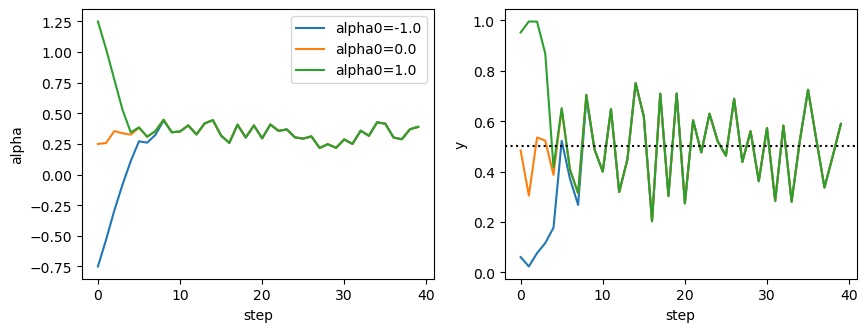

In [ ]:
runs = {}
for a0 in [-1.0, 0.0, 1.0]:
    s = PersonaSim(R, alpha0=a0, seed=1)
    s.system.run(STEPS, show_trace=False, show_loss=False, disable_tqdm=True)
    runs[a0] = s
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a0, s in runs.items():
    ax[0].plot([h.item() for h in s.system.get_node("C").history], label=f"alpha0={a0}")
    ax[1].plot([h.item() for h in s.system.get_node("P1").history])
ax[0].set_ylabel("alpha"); ax[1].set_ylabel("y"); ax[1].axhline(R, color="k", ls=":")
ax[0].legend(); ax[0].set_xlabel("step"); ax[1].set_xlabel("step");

Contraction factor from the package: mean over steps and trials of $|\partial F_k / \partial e_k| = \kappa\,|\partial y_k/\partial\alpha|$ at the visited $\alpha_k$ and drawn personas.

In [ ]:
C = get_factor_from_list(reference_signals=np.array([R]), agent_probs=None, sim_class=PersonaSim,
                         it=STEPS, trials=3, inputs_node="A1", outputs_node="F")
C

array([[0.66936952]])